# 08 · EmoSet-118K: revisión y carga de datos

**EmoSet** (Yang et al., ICCV 2023; `papers/2307.07961v2.pdf`) es un dataset de emociones visuales con **118.102 imágenes**. Cada imagen tiene una de las **8 emociones de Mikels**, cuatro positivas y cuatro negativas, y atributos descriptivos opcionales.

| Positivas | Negativas |
|---|---|
| amusement, awe, contentment, excitement | anger, disgust, fear, sadness |

**Ubicación de los datos**
- **Google Drive:** solo `MyDrive/publicity_analysis/emoset/EmoSet-118K.zip`. En Colab se lee desde el zip, o se descomprime en `/content` para entrenar (`COPIA_LOCAL = True`).
- **Mac:** copia descomprimida en `~/datasets/EmoSet-118K/`, fuera de Drive.
- **No descomprima el zip dentro de Drive:** sus 236.000 archivos tardan días en sincronizarse.

**Contenido del zip** (las carpetas están en la raíz):

```
info.json                       mapeo emoción ↔ índice
train.json / val.json / test.json   listas [emoción, ruta_imagen, ruta_anotación]
image/<emoción>/<id>.jpg
annotation/<emoción>/<id>.json  emotion, brightness, colorfulness y, si existen,
                                scene, object, facial_expression, human_action
```

**Este notebook:**
1. Comprueba que estén todos los archivos y que las particiones sean coherentes: sin solapes, etiquetas consistentes y sin archivos huérfanos.
2. Lee todas las anotaciones y guarda un **índice** (`emoset_index.csv`) para no volver a leer los 118.000 JSON.
3. Describe la distribución de emociones y atributos.
4. Verifica una muestra de imágenes: que abran, su tamaño y su modo de color.
5. Deja DataFrames `path` / `label` compatibles con `pipeline.ImageDataset` (notebook 01).

### ⏱ Tiempo estimado en Colab T4

| Sección | Qué corre | Primera vez | Siguientes |
|---|---|---|---|
| 1. Configuración | Montar Drive; con `COPIA_LOCAL = True`, descomprimir el zip en la VM | < 1 min (10–15 min con copia local) | igual |
| 2–3. Estructura y particiones | Índices JSON | 1–2 min | 1–2 min |
| 4. Anotaciones | Leer 118.000 JSON y guardar `emoset_index.csv` | 10–30 min | < 1 min (lee el CSV) |
| 5. Integridad | Abrir 1.000 imágenes (`N_CHECK`) | 1–3 min | 1–3 min |
| 6–8 | Ejemplos, DataFrames y resumen | 1–3 min | 1–3 min |
| **Total** | | **~15–40 min** | **~5 min** |

No usa GPU. Todo es estimado: depende sobre todo de la velocidad de lectura de Drive. Requiere que `EmoSet-118K.zip` ya esté en `MyDrive/publicity_analysis/emoset/`.

*Supuestos: Colab gratis con T4 y 2 CPU. **Medido** = cronometrado (salidas guardadas o prueba en una máquina de 2 CPU); **estimado** = calculado con el rendimiento publicado de la T4. Con Colab Pro (8 CPU) las partes limitadas por CPU bajan. Las sesiones gratis se cortan a las ~12 h o tras ~90 min sin interacción; lo que dice "reanudable" retoma donde quedó al volver a ejecutar.*

## 1. Configuración

In [13]:
import io
import json
import os
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import zipfile
from PIL import Image

pd.set_option('display.float_format', '{:.3f}'.format)

# Carpeta base publicity_analysis en Google Drive (misma que 01, 04, 06 y 07)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/publicity_analysis'
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    # Fuera de Colab: Google Drive para escritorio (macOS), si está sincronizado
    import glob
    cands = [c for d in ('Mi unidad', 'My Drive')
             for c in glob.glob(os.path.expanduser(f'~/Library/CloudStorage/GoogleDrive-*/{d}/publicity_analysis'))]
    DRIVE_ROOT = next((c for c in cands if os.path.isdir(c)), '.')

EMOSET_DIR = os.path.join(DRIVE_ROOT, 'emoset')
ZIP_PATH = os.path.join(EMOSET_DIR, 'EmoSet-118K.zip')
# La carpeta descomprimida NO se guarda en Drive (236.000 archivos saturan la sincronización).
# Carpeta descomprimida: en Colab, el disco de la VM (con COPIA_LOCAL); en el Mac, ~/datasets.
ROOT = '/content/emoset/EmoSet-118K' if IN_COLAB else os.path.expanduser('~/datasets/EmoSet-118K')
INDEX_CSV = os.path.join(EMOSET_DIR, 'emoset_index.csv')   # caché de las anotaciones
OUT = os.path.join(DRIVE_ROOT, 'resultados', 'emoset')
os.makedirs(OUT, exist_ok=True)

# Fuente de los archivos:
#   'zip'     → se leen desde EmoSet-118K.zip en Drive (Colab). Rápido: un solo archivo grande.
#   'carpeta' → desde la carpeta descomprimida ROOT (Mac en ~/datasets, o Colab con COPIA_LOCAL).
FUENTE = 'carpeta' if os.path.exists(os.path.join(ROOT, 'info.json')) else 'zip'

# Para ENTRENAR en Colab: True descomprime el .zip en el disco de la VM (/content),
# unos 10–15 min una vez por sesión, y todas las rutas apuntan ahí.
COPIA_LOCAL = False
N_CHECK = 1000   # imágenes que se abren para verificar integridad (None = todas; lento)
SEED = 0

if IN_COLAB and COPIA_LOCAL and FUENTE == 'zip':
    # el .zip no trae la carpeta EmoSet-118K/: se descomprime directamente en ROOT
    t = time.time()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(ROOT)
    print(f'Copia local lista en {time.time() - t:.0f}s')
    FUENTE = 'carpeta'

if FUENTE == 'zip':
    assert os.path.exists(ZIP_PATH), f'No se encontró {ZIP_PATH}'
    t = time.time()
    ZIP = zipfile.ZipFile(ZIP_PATH)
    ZIP_NAMES = {n for n in ZIP.namelist() if not n.endswith('/')}
    print(f'Índice del zip leído en {time.time() - t:.1f}s ({len(ZIP_NAMES)} archivos)')

# Acceso a archivos por ruta relativa ('image/awe/awe_00001.jpg'), sea cual sea la fuente
def existe(rel):
    if FUENTE == 'zip':
        return rel in ZIP_NAMES or any(n.startswith(rel.rstrip('/') + '/') for n in ZIP_NAMES)
    return os.path.exists(os.path.join(ROOT, rel))

def leer(rel):
    if FUENTE == 'zip':
        return ZIP.read(rel)
    with open(os.path.join(ROOT, rel), 'rb') as f:
        return f.read()

def abrir_imagen(rel):
    return Image.open(io.BytesIO(leer(rel)))

def ruta(p):
    # Rutas abreviadas, para no mostrar la ruta local completa
    if p.startswith(DRIVE_ROOT):
        return p.replace(DRIVE_ROOT, 'publicity_analysis (Drive)')
    return p.replace(os.path.expanduser('~'), '~')

print('Fuente de datos:', FUENTE, '→', ruta(ZIP_PATH if FUENTE == 'zip' else ROOT))
print('Resultados en:', ruta(OUT))

Fuente de datos: carpeta → ~/datasets/EmoSet-118K
Resultados en: publicity_analysis (Drive)/resultados/emoset


## 2. Estructura de carpetas y archivos de índice

In [14]:
esperados = ['info.json', 'train.json', 'val.json', 'test.json', 'image', 'annotation']
falta = [f for f in esperados if not existe(f)]
assert not falta, f'Faltan en la fuente ({FUENTE}): {falta}'

info = json.loads(leer('info.json'))
LABEL2IDX = info['label2idx']
IDX2LABEL = {int(k): v for k, v in info['idx2label'].items()}
EMOTIONS = [IDX2LABEL[i] for i in range(len(IDX2LABEL))]
POSITIVAS = {'amusement', 'awe', 'contentment', 'excitement'}
assert all(LABEL2IDX[IDX2LABEL[i]] == i for i in IDX2LABEL), 'label2idx e idx2label no coinciden'
print('Emociones:', LABEL2IDX)

# Inventario (con el zip, sale de su índice interno; con la carpeta, un listado por subcarpeta)
en_disco = {}
for sub in ('image', 'annotation'):
    if FUENTE == 'zip':
        en_disco[sub] = {n for n in ZIP_NAMES if n.startswith(sub + '/') and not os.path.basename(n).startswith('.')}
    else:
        en_disco[sub] = {f'{sub}/{c}/{f}' for c in os.listdir(os.path.join(ROOT, sub)) if not c.startswith('.')
                         for f in os.listdir(os.path.join(ROOT, sub, c)) if not f.startswith('.')}
    carpetas = {n.split('/')[1] for n in en_disco[sub]}
    assert carpetas == set(EMOTIONS), f'{sub}: carpetas {sorted(carpetas)}'
    print(f'{sub:<11} {len(en_disco[sub]):>7} archivos')

Emociones: {'amusement': 0, 'awe': 1, 'contentment': 2, 'excitement': 3, 'anger': 4, 'disgust': 5, 'fear': 6, 'sadness': 7}
image        118102 archivos
annotation   118102 archivos


## 3. Particiones: tamaño, solapes y coherencia

In [15]:
filas = []
for split in ('train', 'val', 'test'):
    for emo, img, ann in json.loads(leer(f'{split}.json')):
        filas.append({'split': split, 'emotion': emo, 'image': img, 'annotation': ann})
splits = pd.DataFrame(filas)
splits['image_id'] = splits['image'].str.extract(r'([^/]+)\.\w+$')[0]

chequeos = {
    'imágenes listadas': len(splits),
    'imágenes repetidas (en la misma o en distinta partición)': splits['image'].duplicated().sum(),
    'emoción de la lista ≠ carpeta de la imagen': (splits['emotion'] != splits['image'].str.split('/').str[1]).sum(),
    'emoción fuera de info.json': (~splits['emotion'].isin(EMOTIONS)).sum(),
    'imagen listada que no está en disco': (~splits['image'].isin(en_disco['image'])).sum(),
    'anotación listada que no está en disco': (~splits['annotation'].isin(en_disco['annotation'])).sum(),
    'imágenes en disco que no están en ninguna partición': len(en_disco['image'] - set(splits['image'])),
    'anotaciones en disco que no están en ninguna partición': len(en_disco['annotation'] - set(splits['annotation'])),
}
display(pd.Series(chequeos, name='valor').to_frame())

tabla = pd.crosstab(splits['emotion'], splits['split']).reindex(index=EMOTIONS, columns=['train', 'val', 'test'])
tabla['total'] = tabla.sum(axis=1)
tabla.loc['total'] = tabla.sum()
pct = tabla.div(tabla.loc['total'], axis=1).drop(index='total') * 100
display(tabla)
print('Proporción de cada emoción en cada partición (%):')
display(pct.round(1))

,valor
imágenes listadas,118102
imágenes repetidas (en la misma o en distinta partición),0
emoción de la lista ≠ carpeta de la imagen,0
emoción fuera de info.json,0
imagen listada que no está en disco,0
anotación listada que no está en disco,0
imágenes en disco que no están en ninguna partición,0
anotaciones en disco que no están en ninguna partición,0


split,train,val,test,total
emotion,,,,
amusement,15681,994,2770,19445
awe,12022,755,2260,15037
contentment,13036,817,2484,16337
excitement,15837,977,3014,19828
anger,8434,518,1708,10660
disgust,8467,538,1661,10666
fear,10786,693,1974,13453
sadness,10218,613,1845,12676
total,94481,5905,17716,118102


Proporción de cada emoción en cada partición (%):


split,train,val,test,total
emotion,,,,
amusement,16.600,16.800,15.600,16.500
awe,12.700,12.800,12.800,12.700
contentment,13.800,13.800,14.000,13.800
excitement,16.800,16.500,17.000,16.800
anger,8.900,8.800,9.600,9.000
disgust,9.000,9.100,9.400,9.000
fear,11.400,11.700,11.100,11.400
sadness,10.800,10.400,10.400,10.700


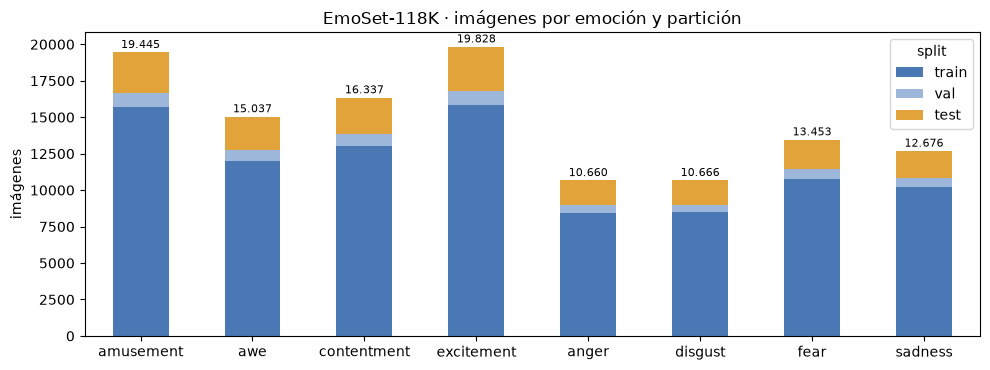

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
t = tabla.drop(index='total')[['train', 'val', 'test']]
t.plot.bar(stacked=True, ax=ax, color=['#4a78b5', '#9db7da', '#e3a33b'])
ax.set(xlabel='', ylabel='imágenes', title='EmoSet-118K · imágenes por emoción y partición')
ax.tick_params(axis='x', rotation=0)
for i, v in enumerate(t.sum(axis=1)):
    ax.text(i, v + 300, f'{v:,}'.replace(',', '.'), ha='center', fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'emociones_por_particion.png'), dpi=150); plt.show()

## 4. Anotaciones

Se leen los 118.000 JSON una sola vez y se guardan en `emoset_index.csv`, junto a la carpeta del dataset. Las ejecuciones siguientes cargan el CSV. Para volver a leer los JSON, borre el CSV.

Con `FUENTE = 'zip'`, los JSON se leen desde el zip en segundos. Abrirlos uno por uno en Drive tomaría entre 10 y 20 minutos o más.

In [17]:
ATTRS = ['brightness', 'colorfulness', 'scene', 'object', 'facial_expression', 'human_action']

if os.path.exists(INDEX_CSV):
    ann = pd.read_csv(INDEX_CSV)
    print(f'Índice cargado desde {ruta(INDEX_CSV)}: {len(ann)} filas')
else:
    t0, rows = time.time(), []
    for k, a in enumerate(splits['annotation']):
        j = json.loads(leer(a))
        obj = j.get('object')
        rows.append({'annotation': a, 'ann_image_id': j.get('image_id'), 'ann_emotion': j.get('emotion'),
                     'brightness': j.get('brightness'), 'colorfulness': j.get('colorfulness'),
                     'scene': j.get('scene'), 'object': '|'.join(obj) if obj else None,
                     'n_objects': len(obj) if obj else 0,
                     'facial_expression': j.get('facial_expression'), 'human_action': j.get('human_action'),
                     'extra_keys': '|'.join(sorted(set(j) - {'image_id', 'emotion', *ATTRS})) or None})
        if (k + 1) % 20000 == 0:
            print(f'  {k + 1}/{len(splits)} ({time.time() - t0:.0f}s)', flush=True)
    ann = splits.merge(pd.DataFrame(rows), on='annotation', how='left')
    ann['label'] = ann['emotion'].map(LABEL2IDX)
    ann['valence'] = np.where(ann['emotion'].isin(POSITIVAS), 'positive', 'negative')
    ann.to_csv(INDEX_CSV, index=False)
    print(f'Leídas {len(ann)} anotaciones en {time.time() - t0:.0f}s → {ruta(INDEX_CSV)}')

print({
    'emoción del JSON ≠ emoción de la partición': int((ann['ann_emotion'] != ann['emotion']).sum()),
    'image_id del JSON ≠ nombre del archivo': int((ann['ann_image_id'] != ann['image_id']).sum()),
    'campos inesperados en algún JSON': ann['extra_keys'].dropna().unique().tolist(),
})
ann.head()

Índice cargado desde publicity_analysis (Drive)/emoset/emoset_index.csv: 118102 filas
{'emoción del JSON ≠ emoción de la partición': 0, 'image_id del JSON ≠ nombre del archivo': 0, 'campos inesperados en algún JSON': []}


,split,emotion,image,annotation,image_id,ann_image_id,ann_emotion,brightness,colorfulness,scene,object,n_objects,facial_expression,human_action,extra_keys,label,valence
0,train,amusement,image/amusement/amusement_08258.jpg,annotation/amusement/amusement_08258.json,amusement_08258,amusement_08258,amusement,0.500,0.600,NaN,NaN,0,happy,NaN,NaN,0,positive
1,train,excitement,image/excitement/excitement_17835.jpg,annotation/excitement/excitement_17835.json,excitement_17835,excitement_17835,excitement,0.500,0.600,street,Hat,1,NaN,hugging,NaN,3,positive
2,train,excitement,image/excitement/excitement_09581.jpg,annotation/excitement/excitement_09581.json,excitement_09581,excitement_09581,excitement,0.500,0.700,NaN,NaN,0,NaN,abseiling,NaN,3,positive
3,train,anger,image/anger/anger_01725.jpg,annotation/anger/anger_01725.json,anger_01725,anger_01725,anger,0.400,0.400,NaN,Wheel|Bicycle wheel|Land vehicle,3,NaN,NaN,NaN,4,negative
4,train,fear,image/fear/fear_10809.jpg,annotation/fear/fear_10809.json,fear_10809,fear_10809,fear,0.400,0.400,NaN,NaN,0,NaN,NaN,NaN,6,negative


### 4b. Cobertura de los atributos

In [18]:
cob = ann[ATTRS].notna().groupby(ann['emotion']).mean().reindex(EMOTIONS) * 100
cob.loc['total'] = ann[ATTRS].notna().mean() * 100
try:
    display(cob.round(1).style.background_gradient(cmap='Blues', axis=None).format('{:.1f}%'))
except (ImportError, AttributeError):   # .style requiere jinja2
    display(cob.round(1))

print('Valores distintos:', {a: ann[a].nunique() for a in ['scene', 'facial_expression', 'human_action']},
      '· objetos distintos:', ann['object'].dropna().str.split('|').explode().nunique())
print('brightness:', sorted(ann['brightness'].dropna().unique()))
print('colorfulness:', sorted(ann['colorfulness'].dropna().unique()))

,brightness,colorfulness,scene,object,facial_expression,human_action
emotion,,,,,,
amusement,99.900,99.800,21.300,56.500,19.600,13.500
awe,99.700,98.700,47.900,48.300,4.100,3.300
contentment,100.000,99.900,15.800,63.100,19.200,16.100
excitement,99.800,98.900,39.700,69.000,31.000,44.400
anger,99.900,92.800,10.000,51.500,13.100,16.700
disgust,99.600,99.200,9.800,40.900,0.300,1.600
fear,99.900,98.000,5.500,35.900,3.400,1.700
sadness,99.500,98.400,27.900,54.900,13.800,9.000
total,99.800,98.500,23.900,54.100,14.700,15.100


Valores distintos: {'scene': 254, 'facial_expression': 6, 'human_action': 264} · objetos distintos: 409
brightness: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0)]
colorfulness: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0)]


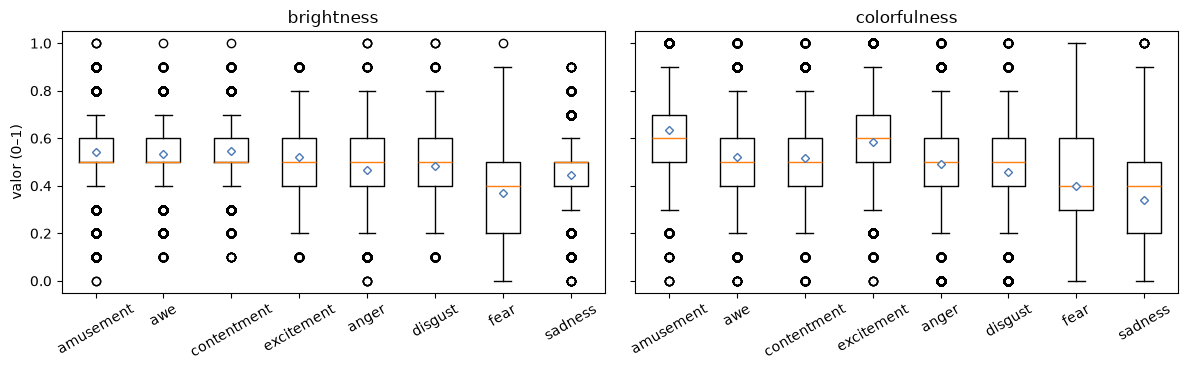

brightness       colorfulness      
                  mean   std         mean   std
emotion                                        
amusement        0.543 0.145        0.633 0.151
awe              0.534 0.124        0.521 0.167
contentment      0.545 0.126        0.517 0.157
excitement       0.523 0.140        0.584 0.167
anger            0.465 0.141        0.491 0.191
disgust          0.483 0.131        0.458 0.171
fear             0.371 0.171        0.400 0.223
sadness          0.445 0.139        0.339 0.214

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, a in zip(axes, ['brightness', 'colorfulness']):
    data = [ann.loc[ann['emotion'] == e, a].dropna() for e in EMOTIONS]
    ax.boxplot(data, showmeans=True, meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='#4a78b5', markersize=4))
    ax.set_xticks(range(1, len(EMOTIONS) + 1), EMOTIONS, rotation=30)
    ax.set_title(a)
axes[0].set_ylabel('valor (0–1)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'brillo_colorido_por_emocion.png'), dpi=150); plt.show()

ann.groupby('emotion')[['brightness', 'colorfulness']].agg(['mean', 'std']).reindex(EMOTIONS)

In [20]:
# Valores más frecuentes de los atributos categóricos, por emoción
def top(col, n=3, explode=False):
    s = ann[['emotion', col]].dropna()
    if explode:
        s = s.assign(**{col: s[col].str.split('|')}).explode(col)
    return (s.groupby('emotion')[col]
             .apply(lambda x: ', '.join(f'{k} ({v / len(x):.0%})' for k, v in x.value_counts().head(n).items()))
             .reindex(EMOTIONS))

pd.DataFrame({'escena': top('scene'), 'objeto': top('object', explode=True),
              'expresión facial': top('facial_expression'), 'acción humana': top('human_action')})

,escena,objeto,expresión facial,acción humana
emotion,,,,
amusement,"amusement_park (43%), carrousel (12%), street ...","Tree (15%), Plant (9%), Flower (4%)","happy (99%), surprise (1%), sad (0%)","laughing (40%), hugging (10%), swinging on som..."
awe,"sky (15%), ocean (7%), mountain_snowy (7%)","Plant (22%), Tree (15%), Building (9%)","happy (83%), surprise (15%), sad (1%)","laughing (12%), hugging (11%), answering quest..."
contentment,"lawn (12%), beach (10%), park (9%)","Plant (19%), Tree (12%), Flower (8%)","happy (99%), surprise (1%), sad (0%)","laughing (21%), hugging (18%), carrying baby (..."
excitement,"street (22%), stage (15%), wave (10%)","Tree (10%), Fashion accessory (8%), Plant (6%)","happy (88%), surprise (11%), angry (1%)","laughing (11%), singing (10%), celebrating (9%)"
anger,"boxing_ring (25%), street (23%), plaza (11%)","Plant (13%), Tree (11%), Jeans (6%)","angry (72%), disgust (12%), happy (8%)","marching (70%), boxing (14%), extinguishing f..."
disgust,"landfill (40%), underwater (22%), butchers_sho...","Plant (16%), Insect (12%), Spider (7%)","disgust (56%), happy (33%), angry (11%)","garbage collecting (68%), smoking (16%), stick..."
fear,"corridor (17%), staircase (9%), street (8%)","House (12%), Building (11%), Plant (9%)","happy (37%), angry (35%), fear (13%)","laughing (23%), stretching arm (18%), sticking..."
sadness,"cemetery (65%), mausoleum (3%), street (3%)","Plant (16%), Tree (13%), House (9%)","sad (97%), angry (1%), happy (1%)","crying (72%), hugging (4%), smoking (2%)"


## 5. Integridad de las imágenes (muestra)

Se abre una muestra aleatoria estratificada por emoción. Se registran las dimensiones, el modo de color y los errores de lectura. `Image.verify()` detecta archivos truncados o corruptos.

In [21]:
muestra = ann.groupby('emotion').sample(n=-(-N_CHECK // len(EMOTIONS)), random_state=SEED) if N_CHECK else ann
t0, rows = time.time(), []
for p in muestra['image']:
    try:
        data = leer(p)
        with Image.open(io.BytesIO(data)) as im:
            w, h, mode, fmt = *im.size, im.mode, im.format
            im.verify()
        rows.append({'image': p, 'width': w, 'height': h, 'mode': mode, 'format': fmt,
                     'bytes': len(data), 'error': None})
    except Exception as e:
        rows.append({'image': p, 'error': f'{type(e).__name__}: {e}'})
img = pd.DataFrame(rows).merge(ann[['image', 'emotion']], on='image')
print(f'{len(img)} imágenes revisadas en {time.time() - t0:.0f}s · errores: {img["error"].notna().sum()}')
if img['error'].notna().any():
    display(img[img['error'].notna()])

ok = img[img['error'].isna()]
print('Modos de color:', ok['mode'].value_counts().to_dict(), '· formatos:', ok['format'].value_counts().to_dict())
display(ok[['width', 'height', 'bytes']].describe(percentiles=[0.05, 0.5, 0.95]).T)
print(f"Lado menor < 224 px: {(ok[['width', 'height']].min(axis=1) < 224).mean():.1%} · "
      f"tamaño medio: {ok['bytes'].mean() / 1024:.0f} KB → dataset completo ≈ {ok['bytes'].mean() * len(ann) / 1024**3:.1f} GB")

1000 imágenes revisadas en 0s · errores: 0
Modos de color: {'RGB': 1000} · formatos: {'JPEG': 1000}


,count,mean,std,min,5%,50%,95%,max
width,1000.000,807.941,255.060,271.000,375.000,768.000,1024.000,3264.000
height,1000.000,736.871,243.222,251.000,375.000,685.000,1024.000,2448.000
bytes,1000.000,94782.930,68921.735,16367.000,32578.850,84806.500,181261.500,1520703.000


Lado menor < 224 px: 0.0% · tamaño medio: 93 KB → dataset completo ≈ 10.4 GB


## 6. Ejemplos por emoción

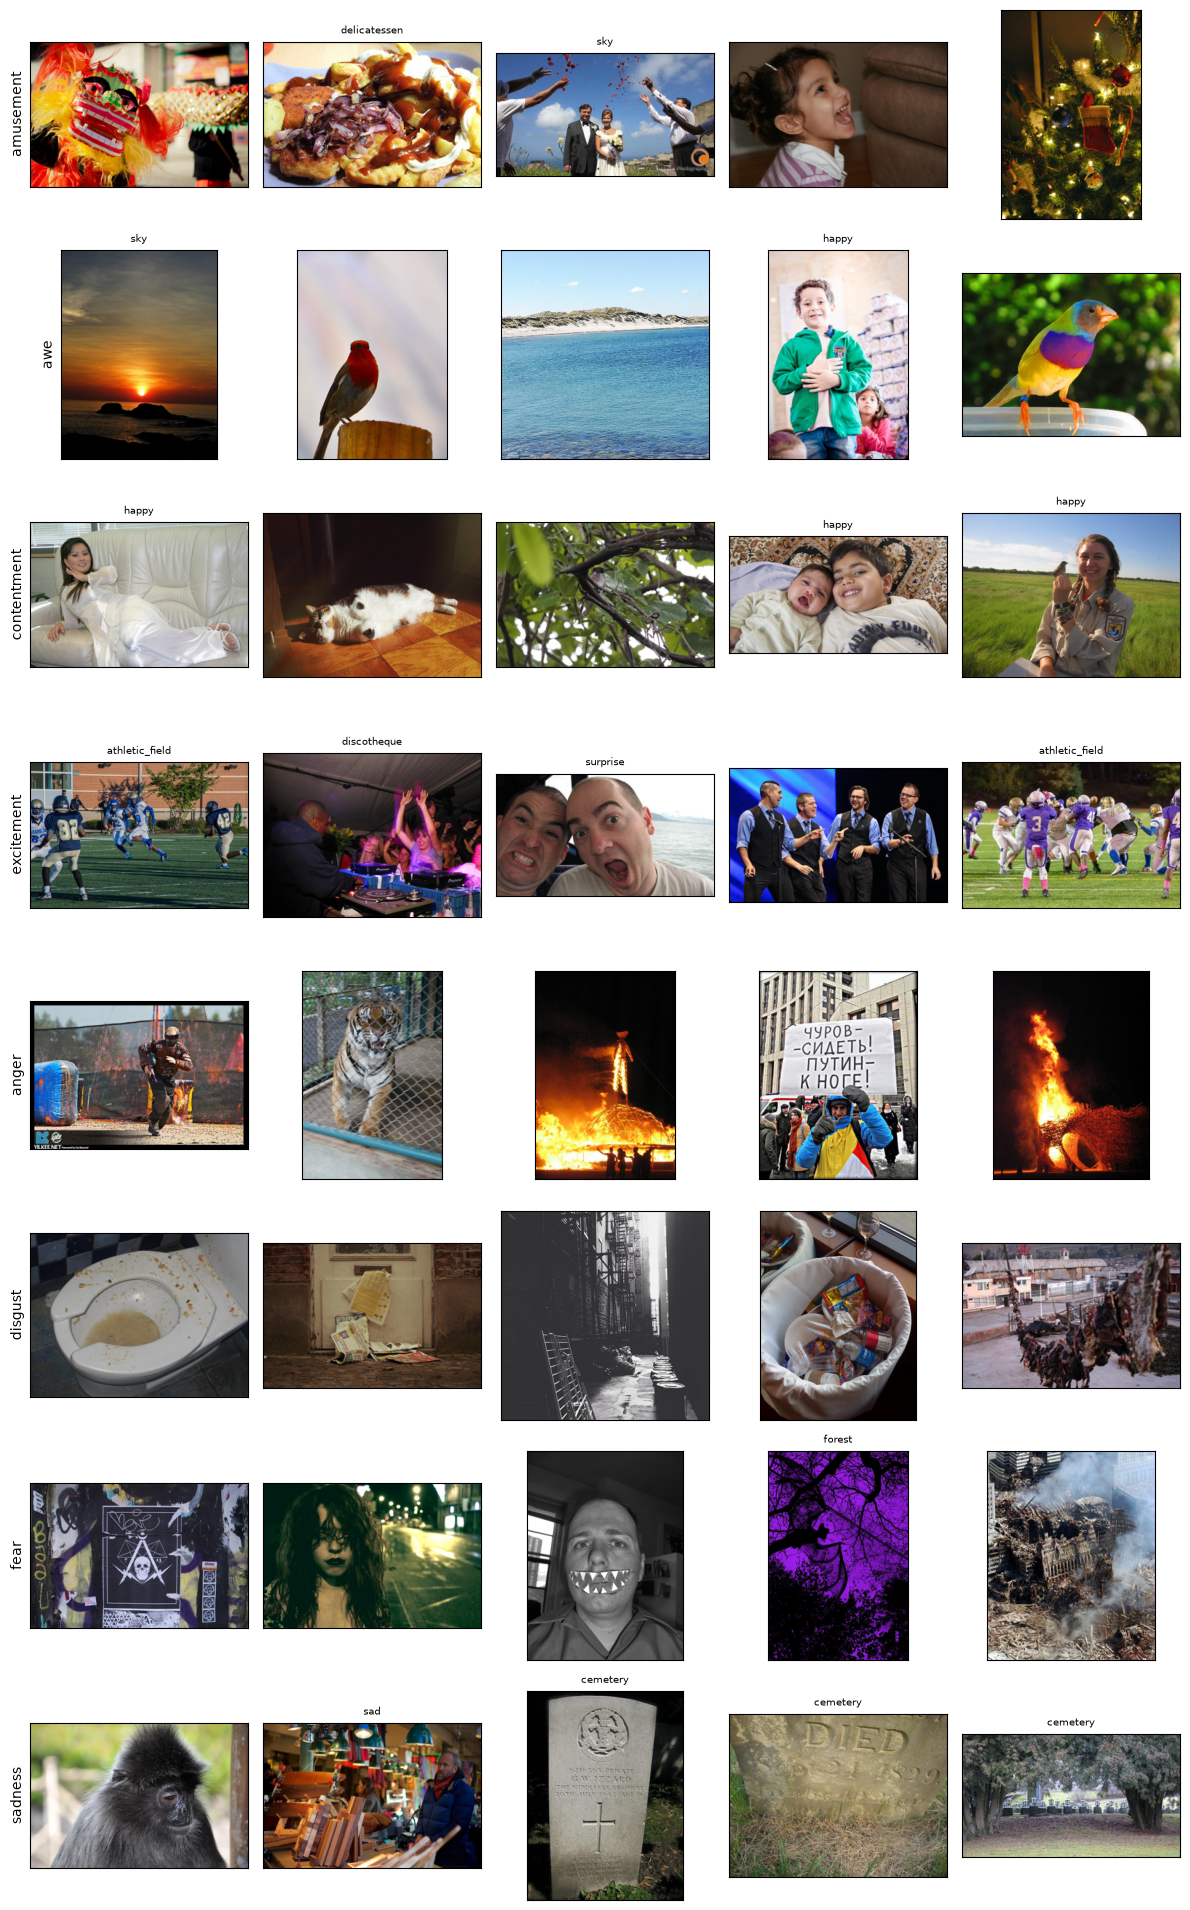

In [22]:
N_COL = 5
fig, axes = plt.subplots(len(EMOTIONS), N_COL, figsize=(N_COL * 2.4, len(EMOTIONS) * 2.4))
rng = random.Random(SEED)
for r, e in enumerate(EMOTIONS):
    sub = ann[ann['emotion'] == e]
    for c, (_, row) in enumerate(sub.sample(N_COL, random_state=rng.randint(0, 10**6)).iterrows()):
        ax = axes[r, c]
        im = abrir_imagen(row['image']).convert('RGB')
        im.thumbnail((300, 300))
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
        extra = row['scene'] if isinstance(row['scene'], str) else (row['facial_expression'] if isinstance(row['facial_expression'], str) else '')
        ax.set_title(extra, fontsize=7)
        if c == 0:
            ax.set_ylabel(e, fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'ejemplos_por_emocion.png'), dpi=110); plt.show()

## 7. Datos listos para entrenar

Se arman DataFrames por partición con las columnas `path` (ruta absoluta) y `label` (índice de `info.json`), el mismo formato que usa `pipeline.ImageDataset` en el notebook 01. También se incluye la valencia (positiva o negativa), por si se quiere un problema de 2 clases.

Las particiones son las **oficiales** de EmoSet (80 % / 5 % / 15 %), así que los resultados son comparables con el paper.

In [23]:
# 'path' = ruta en la carpeta descomprimida (pipeline.ImageDataset); 'image' = ruta dentro del zip.
# Con FUENTE = 'zip' las rutas 'path' no existen: EmoSetDataset lee desde el zip.
ann['path'] = ann['image'].map(lambda p: os.path.join(ROOT, p))
DATA = {s: ann.loc[ann['split'] == s, ['path', 'image', 'label', 'emotion', 'valence', 'image_id']].reset_index(drop=True)
        for s in ('train', 'val', 'test')}
if FUENTE == 'zip':
    print('Datos desde el zip. Para entrenar rápido en Colab: COPIA_LOCAL = True en la sección 1 '
          '(descomprime en el disco de la VM y "path" queda válido para pipeline.ImageDataset).')
for s, d in DATA.items():
    print(f'{s:<5} {len(d):>6} imágenes · valencia positiva {(d["valence"] == "positive").mean():.1%}')

# Ejemplo con PyTorch, si está instalado (en Colab sí)
try:
    import torch
    from torch.utils.data import DataLoader, Dataset
    import torchvision.transforms as T

    class EmoSetDataset(Dataset):
        """Lee desde la carpeta (zip_path=None) o directamente desde el zip."""
        def __init__(self, df, transform, zip_path=None):
            self.paths, self.rel = df['path'].tolist(), df['image'].tolist()
            self.labels, self.transform, self.zip_path = df['label'].tolist(), transform, zip_path
            self._zip, self._pid = None, None
        def __len__(self):
            return len(self.labels)
        def _open(self, i):
            if self.zip_path is None:
                return Image.open(self.paths[i])
            if self._zip is None or self._pid != os.getpid():   # un ZipFile por proceso del DataLoader
                self._zip, self._pid = zipfile.ZipFile(self.zip_path), os.getpid()
            return Image.open(io.BytesIO(self._zip.read(self.rel[i])))
        def __getitem__(self, i):
            return self.transform(self._open(i).convert('RGB')), self.labels[i]

    tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    ds = EmoSetDataset(DATA['val'], tf, zip_path=ZIP_PATH if FUENTE == 'zip' else None)
    loader = DataLoader(ds, batch_size=32, shuffle=True, num_workers=2)
    x, y = next(iter(loader))
    print('Lote de prueba:', tuple(x.shape), '· etiquetas:', [IDX2LABEL[int(i)] for i in y[:8]])
except ImportError:
    print('PyTorch no está instalado aquí: los DataFrames de DATA sirven igual con pipeline.ImageDataset en Colab.')

train  94481 imágenes · valencia positiva 59.9%
val     5905 imágenes · valencia positiva 60.0%
test   17716 imágenes · valencia positiva 59.4%
PyTorch no está instalado aquí: los DataFrames de DATA sirven igual con pipeline.ImageDataset en Colab.


## 8. Resumen

In [24]:
resumen = {
    'imágenes': len(ann),
    'train / val / test': ' / '.join(str((ann['split'] == s).sum()) for s in ('train', 'val', 'test')),
    'emoción más frecuente': f"{ann['emotion'].value_counts().idxmax()} ({ann['emotion'].value_counts(normalize=True).max():.1%})",
    'emoción menos frecuente': f"{ann['emotion'].value_counts().idxmin()} ({ann['emotion'].value_counts(normalize=True).min():.1%})",
    'valencia positiva': f"{(ann['valence'] == 'positive').mean():.1%}",
    'problemas de consistencia': int(sum(v for k, v in chequeos.items() if k != 'imágenes listadas')),
    'imágenes con error (muestra)': f"{img['error'].notna().sum()} de {len(img)}",
    **{f'cobertura {a}': f'{ann[a].notna().mean():.1%}' for a in ATTRS},
}
pd.Series(resumen, name='valor').to_frame()

,valor
imágenes,118102
train / val / test,94481 / 5905 / 17716
emoción más frecuente,excitement (16.8%)
emoción menos frecuente,anger (9.0%)
valencia positiva,59.8%
problemas de consistencia,0
imágenes con error (muestra),0 de 1000
cobertura brightness,99.8%
cobertura colorfulness,98.5%
cobertura scene,23.9%
